# Electromagnetic Shield Design

## Table of Contents
1. **Introduction and Objectives**
2. **Physical Parameters and Constants**
3. **Shield and Superconducting Tape Specifications**
4. **Equilibrium Field Calculations**
5. **Experimental Data Processing**
6. **Meshing and Parameter Space**
7. **Numerical Calculation Core (Numba Integration)**
8. **Execution and Results Visualization**

## Introduction and Objectives

## Introduction and Theoretical Framework
Space missions based on nanosatellite platforms, such as 1U CubeSats, operate in harsh interplanetary radiation environments characterized by continuous fluxes of high-energy charged particles (protons and electrons) originating from the solar wind, alongside ambient interplanetary magnetic fields (IMF). Direct exposure to these plasma streams severely degrades electronic components, damages solar cells, and compromises the integrity of onboard payloads.

To mitigate these environmental hazards, this notebook presents a rigorous preliminary design framework for an **active electromagnetic shielding system** powered by high-temperature superconducting (HTS) Yttrium Barium Copper Oxide ($\text{YBCO}$) coils. The system adopts a **pumpkin configuration** consisting of **4 symmetric arms with 3 coils per arm**, engineered to protect a designated core volume of $1\,\text{U}$ ($10\,\text{cm} \times 10\,\text{cm} \times 10\,\text{cm}$).

#### Governing Physics and Theoretical Principles
The operational mechanics of the active shield rely on two core physical domains:
1. **Magnetostatics (Biot-Savart Law):** The magnetic field $\mathbf{B}(\mathbf{r})$ generated by the superconducting coils carrying a current $I$ along a closed path $C$ is computed via the Biot-Savart law in axisymmetric cylindrical coordinates:
   $$\mathbf{B}(\mathbf{r}) = \frac{\mu_0 I}{4\pi} \int_C \frac{d\mathbf{l}' \times (\mathbf{r} - \mathbf{r}')}{|\mathbf{r} - \mathbf{r}'|^3}$$
   where $\mu_0$ is the vacuum permeability, $d\mathbf{l}'$ is the differential vector element of the coil winding, $\mathbf{r}$ is the field evaluation point, and $\mathbf{r}'$ is the source point along the conductor.
2. **Charged Particle Dynamics (Lorentz Force):** The efficacy of the generated magnetic barrier in deflecting incident solar wind ions is evaluated by tracking individual particle trajectories through the combined field ($\mathbf{B}_{\text{shield}} + \mathbf{B}_{\text{IMF}}$). The relativistic or non-relativistic equation of motion is governed by the Lorentz force law:
   $$\frac{d\mathbf{v}}{dt} = \frac{q}{m} \left( \mathbf{E} + \mathbf{v} \times \mathbf{B} \right)$$
   where $q$ and $m$ represent the charge and mass of the incoming particle (e.g., protons), and $\mathbf{v}$ is its velocity vector.

---

### Numerical Methods and Code Architecture
To handle the computational intensity of evaluating 3D spatial field grids and solving stiff ordinary differential equations (ODEs), this framework integrates high-performance scientific computing libraries:
- **High-Performance JIT Compilation (`Numba`):** The spatial integration kernels for the Biot-Savart law are compiled using Numba (`@njit`) with multithreading support (`TBB` threading layer) and precomputed trigonometric lookup tables (`_crear_tablas_cos`) to bypass Python’s native loop overhead when evaluating dense volumetric meshes.
- **Trajectory Propagation (`SciPy`):** Particle trajectories are integrated using `scipy.integrate.solve_ivp`, applying adaptive step-size Runge-Kutta routines (such as RK45 or DOP853) to solve the initial value problem defined by the Lorentz force equations over discretized temporal domains.
- **Physical Unit Handling (`Astropy`):** All fundamental constants, plasma parameters (number density $n_{\text{sw}}$, thermal velocity $v_{\text{sw}}$), and spatial dimensions are strictly managed using `astropy.units` to guarantee dimensional homogeneity and prevent unit-conversion errors.

---

### Objectives
- **Design** a preliminary active electromagnetic shielding configuration tailored to a $1\,\text{U}$ protected volume utilizing a pumpkin-like geometry (4 arms with 3 coils per arm), accounting for geometrical constraints and typical solar wind plasma parameters ($n_{\text{sw}} \sim 1.5 \times 10^2\,\text{cm}^{-3}$, $v_{\text{sw}} \sim 3000\,\text{km/s}$).
- **Compute** the 3D spatial distribution of the magnetic induction field generated by the YBCO coil arrays using optimized numerical integration of the Biot-Savart law.
- **Verify and Validate** the shielding barrier's mitigation performance by numerically propagating proton trajectories via `solve_ivp` under the influence of the Lorentz force, mapping capture versus deflection cross-sections.

## Preliminary Desing

### Environment Setup and Library Imports

This section initializes the Python environment by importing the core scientific computing, data manipulation, visualization, and physical unit-handling libraries required throughout the notebook. 

* **`astropy` (`units`, `constants`):** Manages physical dimensions, unit conversions, and fundamental astronomical/physical constants to ensure dimensional consistency.
* **`numPy` & `sciPy`:** Powers vectorized array operations, numerical integration structures, and root-finding solvers (`scipy.optimize.newton`).
* **`pandas`:** Handles tabular data structures, such as experimental properties of YBCO superconducting tapes.
* **`matplotlib`:** Generates high-fidelity scientific visualizations, utilizing logarithmic normalization (`LogNorm`) for multi-scale field and flux representations.
* **`tqdm` & `gc`:** Oversees execution progress tracking for intensive parameter sweeps and explicit memory management (garbage collection) during heavy 3D mesh computations.

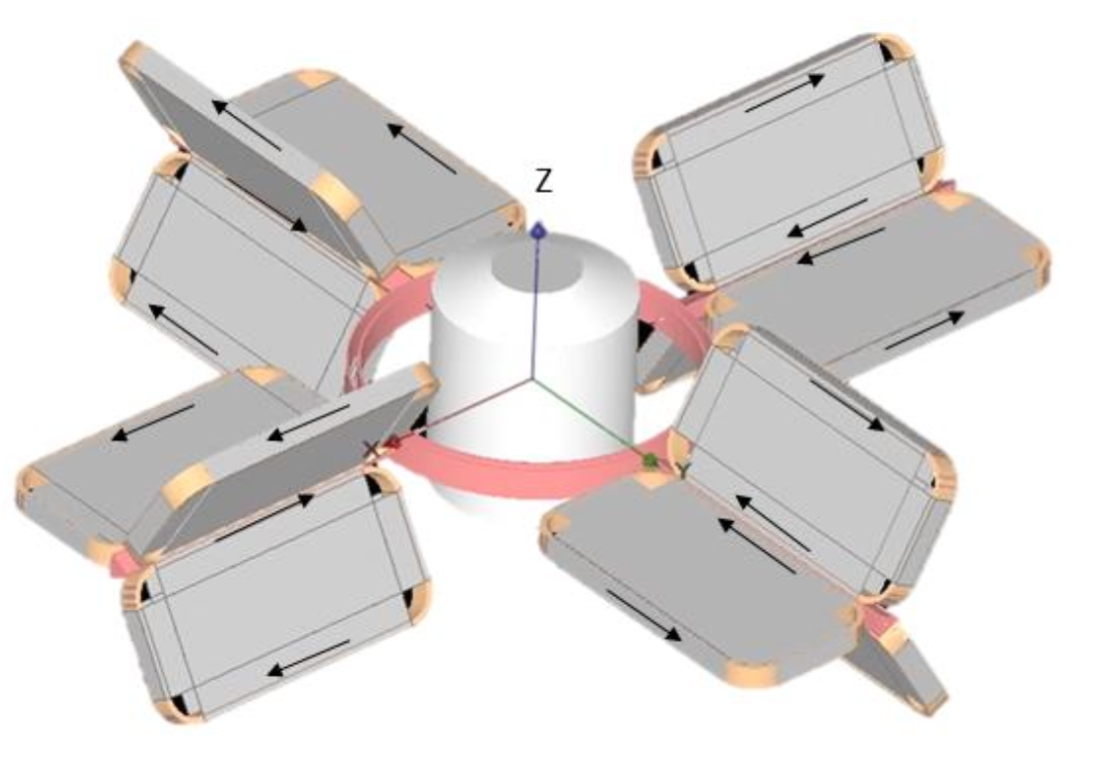

Pumpkin Configuration

In [62]:
# ==========================================
# Environment Setup and Library Imports
# ==========================================

# Physical units and fundamental constants management
from astropy import units as u
from astropy import constants as const

# Core numerical computing and array manipulation
import numpy as np

# Data analysis and tabular manipulation for experimental records
import pandas as pd

# Visualization backends and normalization tools
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# Memory management utilities
import gc

# Function time execution accelerator
from numba import njit, prange, config
from numba_progress import ProgressBar

# Configure Numba threading layer to utilize Intel TBB for efficient parallel execution
config.THREADING_LAYER = 'tbb'


### Solar Wind Plasma Parameters and Physical Constants

This section defines the baseline physical properties of the ambient solar wind environment and fundamental constants required for the electromagnetic shield interaction models. 

**Defined Parameters:**

* **Solar Wind Number Density ($n_{\text{sw}}$):** Set to $1.5 \times 10^2\,\text{cm}^{-3}$.
* **Flow Velocity ($v_{\text{sw}}$):** Set to $3000\,\text{km/s}$ to simulate high-speed stream conditions.
* **Effective Ion-Electron Mass ($m_{\text{sw}}$):** Combined mass of a proton and an electron (`const.m_p + const.m_e`).
* **Plasma Temperature ($T_{\text{sw}}$):** Set to $7 \times 10^6\,\text{K}$.
* **Interplanetary Magnetic Field ($B_{\text{sw}}$):** Background magnetic induction set to $100\,\text{nT}$.
* **Adiabatic Index ($g_{\text{sw}}$):** Set to $5/3$ for a monoatomic ideal gas.
* **Magnetic Pressure Balance ($B_{\text{eq}}$):** The required magnetic induction is derived from the total stagnation pressure (dynamic ram pressure plus thermal plasma pressure) combined with the background magnetic field, scaled by safety factor $\text{FS} = 10$:
   $$B_{\text{eq}} = \text{FS} \cdot \sqrt{2 \mu_0 \left( \rho_{\text{sw}} v_{\text{sw}}^2 + k_B n_{\text{sw}} T_{\text{sw}} \right) + B_{\text{sw}}^2}$$

In [63]:
# ==========================================
# Solar Wind Plasma Parameters and Physical Constants
# ==========================================

# --- Solar Wind Environmental Parameters ---
n_sw = 1.5e2 / u.cm**3                # Solar wind particle number density
v_sw = 3e3 * u.km / u.s                 # Bulk solar wind flow velocity
m_sw = const.m_p + const.m_e            # Effective plasma mass (proton + electron)
T_sw = 7e6 * u.K                        # Bulk plasma temperature
B_sw = 1e2 * u.nT                       # Background interplanetary magnetic field (IMF)
g_sw = 5/3 * u.dimensionless_unscaled   # Adiabatic index (ratio of specific heats for monoatomic gas)

# --- Fundamental Constants (Converted to standard SI scalar values) ---
m_p = const.m_p.to(u.kg).value          # Proton mass in kilograms
q_p = const.e.to(u.C).value             # Elementary charge (proton charge) in Coulombs

mu0 = const.mu0                         # Vacuum permeability (magnetic constant)
kB = const.k_B                          # Boltzmann constant

# --- Derived Plasma Properties ---
rho_sw = n_sw * m_sw                    # Bulk mass density of the solar wind plasma

# Define safety factor for the magnetic shielding design requirement
FS = 10

# Compute the required equilibrium magnetic induction (B_eq) balancing plasma ram pressure, 
# thermal pressure, and background magnetic field, scaled by the safety factor (FS)
B_eq = FS * ( 2 * mu0 * (rho_sw * v_sw**2 + kB * n_sw * T_sw) + B_sw**2 )**0.5
display(B_eq.to(u.uT))

<Quantity 23.92613154 uT>

### Shield Geometry and YBCO Superconducting Tape Specifications

This section defines the geometric design boundaries for the electromagnetic shield and the material specifications of the YBCO (Yttrium Barium Copper Oxide) high-temperature superconducting tape used to construct the coils.

**Design Parameters:**
* **Shield Characteristic Length ($L_{\text{shield}}$):** Baseline length scale of $10\,\text{cm}$, corresponding to the dimensions of the $1\,\text{U}$ protected core volume.
* **Geometrical Envelopes ($R_{\text{max}}, H_{\text{max}}$):** Maximum allowable radius ($10\,\text{cm}$) and height ($20\,\text{cm}$) constraints for the spacecraft accommodation layout.
* **Superconducting Tape Properties:** 
  * Material density ($\rho_{\text{tape}}$): $7697\,\text{kg/m}^3$.
  * Total volume ($\text{volume}_{\text{tape}}$) and length ($L_{\text{tape}}$): $1.16 \times 10^{-4}\,\text{m}^3$ and $315\,\text{m}$.
  * Tape dimensions ($l_{\text{tape}}, lV_{\text{tape}}, w_{\text{tape}}$): Length, voltage tap spacing, and width ($4\,\text{mm}$).
  * Critical voltage threshold ($V_{c,\text{tape}}$): $5\,\mu\text{V}$ criterion for critical current definition.
  * **Tape Dimensions ($t_{\text{tape}}, A_{\text{tape}}$):** Assuming a uniform rectangular cross-section, the tape thickness $t_{\text{tape}}$ is evaluated from the total volume and winding length, subsequently yielding the cross-sectional area $A_{\text{tape}} = w_{\text{tape}} t_{\text{tape}}$.

In [40]:
# ==========================================
# Shield Geometry and YBCO Superconducting Tape Specifications
# ==========================================

# --- System-Level Dimensional Constraints ---
L_shield = 10 * u.cm                  # Characteristic length scale corresponding to the 1U volume

# --- Geometrical Envelope Boundaries ---
R_max = 10 * u.cm                     # Maximum allowable radius for the shield configuration
H_max = 20 * u.cm                     # Maximum allowable axial height for the coil assembly

# --- YBCO Superconducting Tape Electromechanical Properties ---
rho_tape = 7697 * u.kg / u.m**3       # Volumetric mass density of the YBCO tape composite
volume_tape = 1.16e-4 * u.m**3        # Total volume of superconducting tape allocated
L_tape = 315 * u.m                    # Total available length of the tape winding
l_tape = 2.5 * u.cm                   # Segment or sub-element tape length scale
lV_tape = 5 * u.mm                    # Voltage tap distance specification
w_tape = 4 * u.mm                     # Tape width
Vc_tape = 5 * u.uV                    # Critical electric field voltage criterion ($5\,\mu\text{V}$)

# Derive the effective thickness of the YBCO tape from total volume, length, and width constraints
t_tape = volume_tape / (L_tape * w_tape)

# Compute the cross-sectional area of the superconducting tape
A_tape = w_tape * t_tape
display(A_tape.to(u.mm**2))

<Quantity 0.36825397 mm2>

### Experimental YBCO Tape Data Processing and Filtering

To ensure that the superconducting coils operate reliably under the computed equilibrium magnetic field ($B_{\text{eq}}$) and cryogenic temperature constraints, this section processes and filters empirical characterization data (`data_YBCO.xlsx`).

**Processing Pipeline**
1. **Data Cleaning:** Replaces missing string indicators (`"--"`) with `NaN` values, drops incomplete records, and casts the dataset into floating-point numerical types.
2. **Magnetic Field Filtering:** Filters the dataset to retain only records where the applied magnetic field meets or exceeds the required equilibrium threshold ($B_{\text{eq}}$).
3. **Temperature Constraint Filtering:** Restricts the operating temperature to cryogenic conditions, bounded by liquid nitrogen temperature ($T_{\text{min}} = 77\,\text{K}$).
4. **Critical Current Optimization ($I_c$):** Isolates the maximum available critical current ($I_c$) performance tier matching the operational regime of the selected YBCO tape.

In [41]:
# ==========================================
# Experimental YBCO Tape Data Processing and Filtering
# ==========================================

# Define the minimum operating cryogenic temperature (Liquid Nitrogen boiling point)
T_min = 77 * u.K

# Load the raw experimental characterization data for the YBCO tape from an Excel spreadsheet
YBCO = pd.read_excel("data_YBCO.xlsx")

# Clean placeholder strings, remove null entries, and cast all data fields to floating-point values
YBCO = YBCO.replace("--", np.nan)
YBCO = YBCO.dropna()
YBCO = YBCO.astype(float)

# Filter dataset to retain data points where the set magnetic field is greater than or equal to B_eq
YBCO = YBCO[YBCO["Set field (T)"] >= B_eq.to_value(u.T)]

# Filter dataset by temperature bounds relative to the 77 K cryogenic threshold
YBCO = YBCO[YBCO["Set temperature (K)"] >= min(YBCO["Set temperature (K)"].max(), T_min.to_value(u.K))]

# Isolate records meeting or exceeding the maximum critical current (Ic) performance requirement
YBCO = YBCO[YBCO["Ic (A)"] >= YBCO["Ic (A)"].max()]

# Display the filtered dataframe containing the operating point characteristics
YBCO

,Temperature (K),Field (T),Angle (°),Ic/w (A/cm),Ic (A),n,V0 (µV),V1 (µV/A),Hall field (T),Hall angle (°),Set temperature (K),Set field (T),Set angle (°)
14356,77.5,0.01,5.0,512.8,51.28,25.2,-0.03714,0.00029,0.009,10.38,77.5,0.01,5.0


### Parameter Space Discretization and Mesh Generation

To evaluate optimal configurations for the electromagnetic shield, this section constructs a multidimensional parameter space by discretizing current, turn counts, and winding thicknesses.

**Modeling Grid Variables:**
* **Current Array ($I_s$):** Discretized from $1\,\text{A}$ up to the maximum critical current $I_c$ extracted from the YBCO data, with a step size $\text{di} = 1\,\text{A}$.
* **Thickness Array ($t_s$):** Sweeps across tape dimension limits bounded by the minimum and maximum of the tape width ($w_{\text{tape}}$) and thickness ($t_{\text{tape}}$).
* **Turn Count Array ($N_s$):** Discretized integer count of turns ranging from $1$ up to the geometric limit defined by maximum axial height ($H_{\text{max}}$) divided by the minimum tape feature size, using a step $\text{dn} = 5$.
* **Tensor Grid Generation (`meshgrid`):** Combines these arrays into a 3D computational space (`I_s`, `N_s`, `T_s`) to evaluate derived configurations such as total stack height ($H_s$), overall current density ($J_s$), and winding width ($W_s$).

In [42]:
# ==========================================
# Parameter Space Discretization and Mesh Generation
# ==========================================

# --- Current Discretization ---
di = 1
# Generate array of current values from 1 A up to the maximum experimental Ic value
i_s = np.arange(1, np.floor(YBCO["Ic (A)"].max()) + di, di) * u.A

# --- Thickness Discretization ---
# Define step size based on the minimum physical dimension of the YBCO tape
dt = 1 * min(w_tape, t_tape).to_value(u.m)
# Generate thickness range between tape minimum and maximum cross-sectional bounds
t_s = np.arange(min(w_tape, t_tape).to_value(u.m), max(w_tape, t_tape).to_value(u.m) + dt, dt) * u.m

# --- Turn Count Discretization ---
dn = 5
# Generate dimensionless integer array for the number of coil turns constrained by H_max
n_s = np.arange(1, (H_max / min(w_tape, t_tape)).to(u.m/u.m) + dn, dn, dtype=int) * u.dimensionless_unscaled

# --- 3D Parameter Space Mesh Generation ---
# Construct a multi-dimensional meshgrid for currents, turn counts, and tape thicknesses using indexing 'ij'
I_s, N_s, T_s = np.meshgrid(i_s, n_s, t_s, indexing='ij')

# --- Derived Design Parameter Matrices ---
H_s = T_s * N_s                  # Total stack height matrix derived from thickness and turns
J_s = I_s / A_tape               # Current density matrix across the tape cross-sectional area
W_s = A_tape / T_s               # Effective winding width matrix

### Numerical Calculation Core: Biot-Savart Integration & Optimization (Numba Accelerated)

To efficiently compute the 3D magnetic induction field and solve for the coil radius across large parameter spaces, this section implements high-performance numerical routines accelerated via **Numba** (`@njit`) with multi-threading support (`TBB` threading layer).

**Computational Architecture:**
1. **Trigonometric Precomputation (`_crear_tablas_cos`):** Precalculates cosine lookup tables across multi-level resolutions to bypass repetitive trigonometric evaluations during innermost spatial loops.
2. **Adaptive Biot-Savart Kernel (`_int_bs_rz` & `B_bs_z0`):** Evaluates the spatial magnetic field components in cylindrical coordinates $(r, z)$ through adaptive mesh refinement (doubling radial and axial sub-divisions $nr, nz$ iteratively) until convergence criteria (`tol`) are met. Richardson extrapolation (`b_interp`) is applied to accelerate integration accuracy.
3. **Objective Function (`f_obj`):** Formulates the normalized residual between the target equilibrium magnetic field ($B_{\text{obj}}$) and the computed coil field.
4. **Parallelized Optimization Loop (`minimize_B_obj`):** Executes parallelized root-finding sweeps over flattened design grids using Newton-Raphson iterations with adaptive damping and bounds checks to isolate viable coil geometries.

In [43]:
# ==========================================
# Numerical Calculation Core: Biot-Savart Integration & Optimization
# ==========================================
@njit
def _crear_tablas_cos(nphi_base, max_iter):
    """
    Precomputes cosine lookup tables at multi-level refinement resolutions 
    to accelerate azimuthal angle integrations in cylindrical coordinates.
    """
    tablas = []
    n = nphi_base
    for _ in range(max_iter + 1):
        dphi = np.pi / n
        tablas.append(np.cos((np.arange(n) + 0.5) * dphi))
        n *= 2
    return tablas

@njit
def _int_bs_rz(d, z, R1, t, L, nr, nz, cos_phis):
    """
    Computes the Biot-Savart magnetic field integral in axisymmetric cylindrical coordinates 
    (r, z) for a finite coil geometry characterized by thickness (t) and length (L).
    """
    nphi = len(cos_phis)
    r = R1 + t + d
    dr = t / nr
    dz = L / nz   
    dphi = np.pi / nphi
    suma_r = 0.0
    suma_z = 0.0
    
    # Nested loops over radial divisions (ir), axial divisions (iz), and azimuthal angles (iphi)
    for ir in range(nr):
        rp = R1 + (ir + 0.5) * dr
        diff_r2 = (r - rp) ** 2
        for iz in range(nz):
            zp = -0.5 * L + (iz + 0.5) * dz
            dz_rel = z - zp
            base_dist2 = diff_r2 + dz_rel * dz_rel
            for iphi in range(nphi):
                cos_phi = cos_phis[iphi]
                dist2 = base_dist2 + 2.0 * r * rp * (1.0 - cos_phi)
                dist3 = dist2 * np.sqrt(dist2)
                suma_r += (rp * dz_rel * cos_phi) / dist3
                suma_z += (rp * (rp - r * cos_phi)) / dist3
                
    dV = dr * dz * dphi
    return (suma_r * suma_r + suma_z * suma_z)**0.5 * dV


@njit
def B_bs_z0(d, z, N, I, R1, t, L, mu0, tol, max_iter, cos_tablas):
    """
    Calculates the total magnetic induction magnitude using adaptive mesh refinement 
    and Richardson extrapolation for convergence acceleration.
    """
    nr, nz = 4, 4
    b_anterior = _int_bs_rz(d, z, R1, t, L, nr, nz, cos_tablas[0])
    b_interp = b_anterior
    
    # Iterative refinement loop doubling grid density until convergence tolerance is achieved
    for k in range(1, max_iter + 1):
        nr *= 2
        nz *= 2
        b_actual = _int_bs_rz(d, z, R1, t, L, nr, nz, cos_tablas[k])
        b_interp = ( 4 * b_actual - b_anterior ) / 3
        if abs(b_actual - b_anterior) < tol:
            break    
        b_anterior = b_actual         
    return (mu0 * N * I / (L * t) / np.pi) * np.abs(b_interp)


@njit
def f_obj(B, d, z, N, I, R, t, L, mu0, tol, max_iter, cos_tablas):
    """
    Objective function defining the normalized residual between the target field 
    and the evaluated Biot-Savart field magnitude.
    """
    return (B - B_bs_z0(d, z, N, I, R, t, L, mu0, tol, max_iter, cos_tablas)) / B


@njit(parallel=True)
def minimize_B_obj(B_obj, d, z, N, I, T, L, MASK, mu0, eps, tol, max_iter_x, max_iter_f, progress):
    """
    Parallelized optimization routine using Newton-Raphson iterations to solve for 
    the optimal coil inner radius satisfying the target magnetic field requirement.
    """
    cos_tablas = _crear_tablas_cos(32, max_iter_f)
    N, I, L, T, MASK = N.ravel(), I.ravel(), L.ravel(), T.ravel(), MASK.ravel()
    R = np.full(len(L), np.nan)
    F = np.full(len(L), np.nan)
    
    # Parallelized sweep over parameter space indices using prange
    for idx in prange(len(L)):
        if MASK[idx] == True:
            n = N[idx]
            i = I[idx]
            l = L[idx]
            t = T[idx]
            x = 0.0 # Initial guess for radius
            f =  f_obj(B_obj, d, z, n, i, x, t, l, mu0, tol, max_iter_f, cos_tablas)
            df = (f_obj(B_obj, d, z, n, i, x + eps, t, l, mu0, tol, max_iter_f, cos_tablas) - f) / eps
            helper = 1.0            
            
            # Newton-Raphson root-finding iterations with adaptive step damping
            for _ in range(max_iter_x):
                dx = f / df
                x_ = x - dx
                if x_ <= 0:
                    x_ = x + helper * dx
                    helper += helper
                x = x_
                f =  f_obj(B_obj, d, z, n, i, x, t, l, mu0, tol, max_iter_f, cos_tablas)
                df = (f_obj(B_obj, d, z, n, i, x + eps, t, l, mu0, tol, max_iter_f, cos_tablas) - f) / eps
                if abs(f) < tol:
                    break
                if ~np.isfinite(f) or df == 0:
                    x = np.nan
                    f = np.nan
                    break
            R[idx] = x
            F[idx] = f
        progress.update(1)
    return R, F

### Execution of the Optimization Sweep & Analytical Approximations

This section executes the Numba-accelerated parallel optimization sweep over the defined multidimensional parameter space, solving for the optimal inner radius ($R_s$) of the superconducting coils that satisfies the target magnetic field requirement ($B_{\text{eq}}$).

**Execution Workflow**
1. **Progress Tracking (`ProgressBar`):** Wraps the parallel execution loop to monitor computational progress across all elements of the parameter grid ($H_s.size$).
2. **Parameter Unpacking & Scaling:** Passes unit-converted values for target magnetic field ($B_{\text{eq}}$), evaluation coordinates ($d, z$), coil turn counts ($N$), currents ($I$), winding widths ($T$), lengths ($L$), and numerical tolerances into `minimize_B_obj`.
3. **Reshaping and Filtering:** Reshapes the returned flattened output arrays back into the original multi-dimensional tensor shapes and filters non-physical or negative radii (`<= 0`) by assigning `NaN` values.
4. **Analytical Reference (`R_inf_s`):** Computes an infinite-solenoid analytical approximation for the radius to serve as a baseline comparison against the finite-geometry numerical results.

In [44]:
# ==========================================
# 9. Execution of the Optimization Sweep & Analytical Approximations
# ==========================================

# Execute the parallelized optimization sweep using a progress bar to track iterations over the entire mesh size
with ProgressBar(total=H_s.size) as progress:
    R_s, F_s = minimize_B_obj(
        B_obj      = B_eq.to_value(u.T),
        d          = 0.5 * L_shield.to_value(u.m),
        z          = 0.5 * L_shield.to_value(u.m),
        N          = N_s.to_value(u.dimensionless_unscaled),
        I          = I_s.to_value(u.A),
        T          = W_s.to_value(u.m),
        L          = H_s.to_value(u.m),
        MASK       = np.full(N_s.shape, True),
        mu0        = mu0.to_value(u.N / u.A**2), 
        eps        = 1e-1*1e1**np.floor(np.log10(min(t_tape, w_tape).to_value(u.m))), # Perturbation step for derivative
        tol        = 1e-1*1e1**np.floor(np.log10(min(t_tape, w_tape).to_value(u.m))), # Convergence tolerance threshold
        max_iter_x = 10000,
        max_iter_f = 0,
        progress   = progress 
    )

# Reshape flattened optimization outputs back to match the original multi-dimensional grid shape
F_s = F_s.reshape(H_s.shape)

# Convert resolved radii back to Astropy length units and mask non-physical values (<= 0)
R_s = R_s.reshape(H_s.shape) * u.m
R_s[R_s <= 0] = np.nan

# Compute an analytical infinite-solenoid radius approximation for comparative benchmarking
R_inf_s = const.mu0 * N_s * I_s / (2 * B_eq) - 0.5 * L_shield
R_inf_s[R_inf_s <= 0] = np.nan

  0%|          | 0/978384 [00:00<?, ?it/s]

### Visualization of Optimization Results

This section generates scientific heatmaps to evaluate the performance and physical constraints across the discretized parameter space ($N$ vs. $I$).

**Visualization Outputs**
1. **Convergence / Relative Error Map (`F_s`):** Plots the maximum absolute relative error (`B_mag Max Relative Error`) on a logarithmic scale (`LogNorm`, `inferno` colormap) to verify numerical convergence across all solved coil configurations.
2. **Coil Radius Distribution Map (`R_s`):** Maps the minimum resolved inner radius (`Min Internal Coil Radius [m]`) across turn counts and operating currents, ensuring the physical dimensions comply with the $1\,\text{U}$ system envelope constraints.

/tmp/ipykernel_42157/2819844964.py:4: RuntimeWarning: All-NaN slice encountered
  np.nanmax(np.abs(F_s), axis=-1), # Maximum absolute relative error projected along the thickness axis
/tmp/ipykernel_42157/2819844964.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


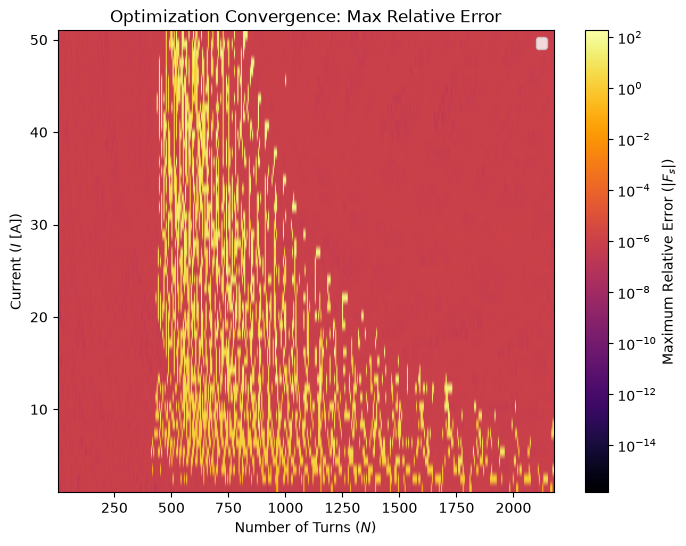

In [45]:
# --- Plot 1: Maximum Relative Error Map (Convergence Verification) ---
plt.figure(figsize=(8, 6))
plt.imshow(
    np.nanmax(np.abs(F_s), axis=-1), # Maximum absolute relative error projected along the thickness axis
    extent=[N_s.value.min(), N_s.value.max(), I_s.to(u.A).value.min(), I_s.to(u.A).value.max()],
    origin='lower',
    aspect='auto',
    cmap='inferno',
    norm=LogNorm(vmin=np.nanmin(np.abs(F_s)), vmax=np.nanmax(np.abs(F_s))) # Logarithmic color scaling for residual error
)

plt.xlabel("Number of Turns ($N$)")
plt.ylabel("Current ($I$ [A])")
plt.colorbar(label=r"Maximum Relative Error ($|F_s|$)")
plt.title("Optimization Convergence: Max Relative Error")
plt.legend()
plt.show()

/tmp/ipykernel_42157/1661766044.py:4: RuntimeWarning: All-NaN slice encountered
  np.nanmin(R_s.to_value(u.m), axis=-1), # Minimum resolved inner radius projected along the thickness axis
/tmp/ipykernel_42157/1661766044.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


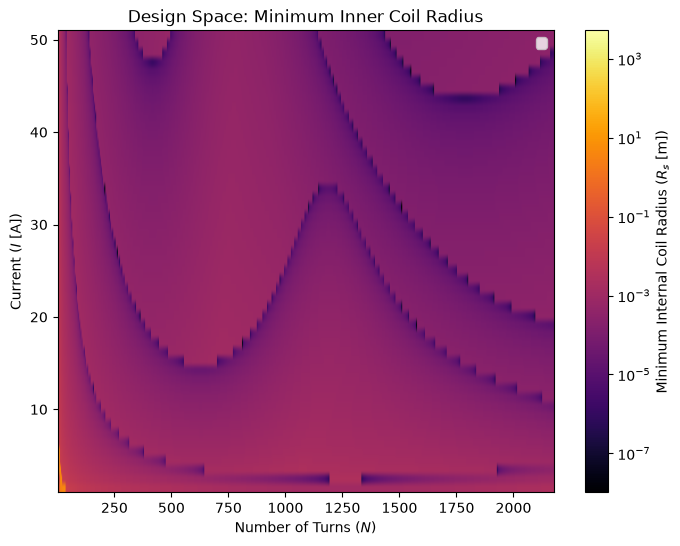

In [46]:
# --- Plot 2: Minimum Internal Coil Radius Map ---
plt.figure(figsize=(8, 6))
plt.imshow(
    np.nanmin(R_s.to_value(u.m), axis=-1), # Minimum resolved inner radius projected along the thickness axis
    extent=[N_s.value.min(), N_s.value.max(), I_s.to(u.A).value.min(), I_s.to(u.A).value.max()],
    origin='lower',
    aspect='auto',
    cmap='inferno',
    norm=LogNorm(vmin=np.nanmin(R_s.to_value(u.m)), vmax=np.nanmax(R_s.to_value(u.m))) # Logarithmic color scaling for radius
)

plt.xlabel("Number of Turns ($N$)")
plt.ylabel("Current ($I$ [A])")
plt.colorbar(label=r"Minimum Internal Coil Radius ($R_s$ [m])")
plt.title("Design Space: Minimum Inner Coil Radius")
plt.legend()
plt.show()

### Superconducting Coil Mass Estimation and Optimization Analysis

Once the optimal inner coil radius ($R_s$) is resolved across the parameter space, this section evaluates the physical mass requirements of the YBCO superconducting winding configuration.

**Mass Calculation Methodology:**
1. **Total Wire Length ($L_s$):** Estimated as a function of the mean coil circumference and the total number of turns:
   $$L_s = 2 \pi R_s N_s$$
2. **Total Coil Volume ($\text{volume}_s$):** Derived from the total length multiplied by the cross-sectional area of the superconducting tape ($\text{volume}_s = L_s A_{\text{tape}}$).
3. **Coil Mass ($m_s$):** Evaluated by multiplying the total volume by the volumetric mass density of the YBCO composite tape ($\rho_{\text{tape}} = 7697\,\text{kg/m}^3$).
4. **Mass Distribution Map:** Generates a logarithmic heatmap displaying the minimum achievable coil mass across the design space ($N$ vs. $I$), allowing identification of lightweight configurations compliant with nanosatellite payload limits.

/home/santy/Projects/GitProjects/SW-suite/.venv/lib/python3.12/site-packages/astropy/units/quantity.py:1892: RuntimeWarning: All-NaN axis encountered
  return super().__array_function__(function, types, args, kwargs)
/tmp/ipykernel_42157/2943452358.py:26: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


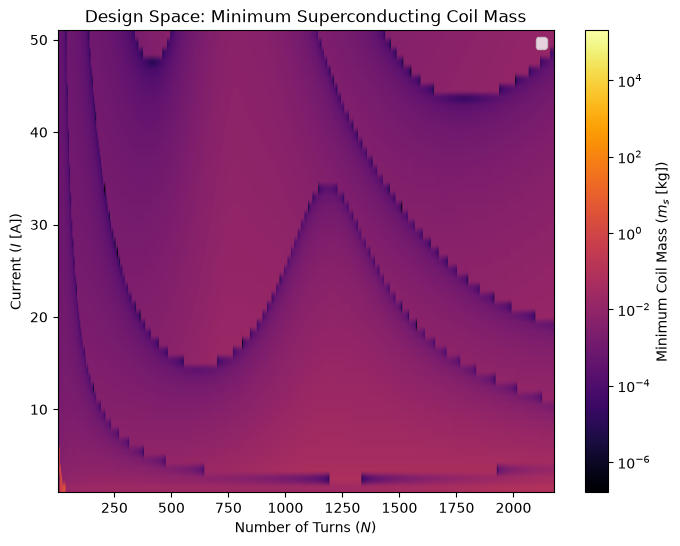

In [47]:
# ==========================================
# Superconducting Coil Mass Estimation and Optimization Analysis
# ==========================================

# --- Mass and Geometric Derived Computations ---
L_s = 2 * np.pi * R_s * N_s               # Total length of the superconducting winding tape [m]
volume_s = L_s * A_tape                   # Total volume of the coil winding [m^3]
m_s = rho_tape * volume_s                 # Total mass of the YBCO superconducting coil [kg]

# --- Visualization: Minimum Coil Mass Map ---
plt.figure(figsize=(8, 6))
plt.imshow(
    np.nanmin(m_s, axis=-1).to_value(u.kg), # Minimum projected mass along the thickness axis
    extent=[N_s.value.min(), N_s.value.max(), I_s.to(u.A).value.min(), I_s.to(u.A).value.max()],
    origin='lower',
    aspect='auto',
    cmap='inferno',
    norm=LogNorm(vmin=np.nanmin(m_s.to_value(u.kg)), vmax=np.nanmax(m_s.to_value(u.kg))) # Logarithmic colormap scaling
)

plt.xlabel("Number of Turns ($N$)")
plt.ylabel("Current ($I$ [A])")
plt.colorbar(label=r"Minimum Coil Mass ($m_s$ [kg])")
plt.title("Design Space: Minimum Superconducting Coil Mass")
#plt.xscale("log") # Optional logarithmic scaling for turn count axis if required
plt.legend()
plt.show()

### Electrical Characterization, Voltage-Current Modeling, and Power Dissipation

To evaluate the operational stability and power consumption of the superconducting coils, this section models the non-linear voltage-current ($V-I$) response of the YBCO tape and computes total power dissipation across the design space.

**Governing Electrical Relations:**

1. **$V-I$ Power-Law Characteristic:** The voltage response of the superconducting tape incorporates flux-flow resistivity, critical current transitions, and the power-law exponent index ($n$):
   $$V(I) = V_c \left(\frac{I}{I_c}\right)^n + V_1 I + V_0$$
   where $V_c$ is the critical voltage criterion, $I_c$ is the experimental critical current, and $V_0, V_1$ represent empirical correction terms.
2. **Total Tape Voltage ($V_s$):** Scales the elementary tape voltage behavior by the total winding length ($L_s$) normalized by the voltage tap distance ($lV_{\text{tape}}$), taking the maximum envelope across characterization criteria.
3. **Power Dissipation ($P_s$):** Computed as the product of the total coil voltage and operating current ($P_s = V_s I_s$), mapped across the parameter space to ensure cryocooler thermal loads remain within feasible nanosatellite power budgets.

/tmp/ipykernel_42157/201867655.py:40: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


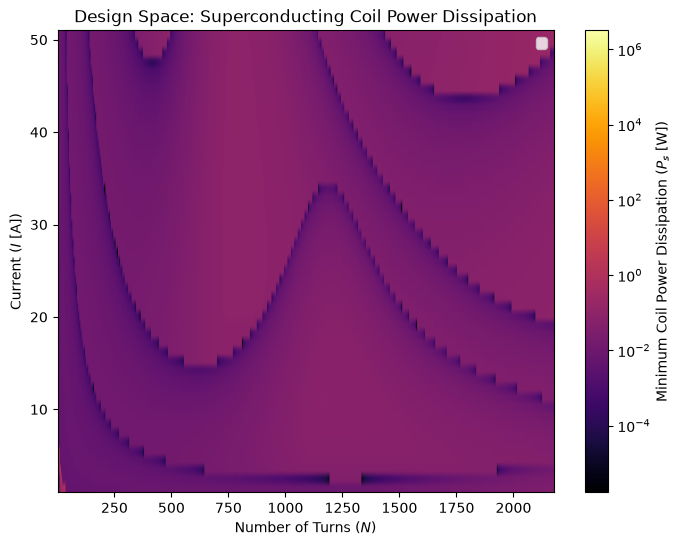

In [48]:
# ==========================================
# Electrical Characterization, Voltage-Current Modeling, and Power Dissipation
# ==========================================

# --- Voltage-Current (V-I) Power-Law Modeling ---
# Computes the total coil voltage (V_s) based on the empirical power-law relation, 
# incorporating critical current (Ic), exponent (n), and resistive voltage drop terms (V0, V1).
V_s = np.nanmax([
    (
        YBCO["V0 (µV)"].values * u.uV
        + 
        YBCO["V1 (µV/A)"].values * u.uV / u.A * I_s
        +
        Vc_tape * (I_s / (YBCO["Ic (A)"].values * u.A))**YBCO["n"].values
    ).to_value(u.V),
    (
        Vc_tape * (I_s / (YBCO["Ic (A)"].values * u.A))**YBCO["n"].values
    ).to_value(u.V),
    ])* L_s / lV_tape * u.V

# --- Power Dissipation Calculation ---
# Total electrical power dissipation (P_s) in Watts across the superconducting winding
P_s = V_s * I_s

# --- Visualization: Minimum Coil Power Dissipation Map ---
plt.figure(figsize=(8, 6))
plt.imshow(
    np.nanmin(P_s, axis=-1).to_value(u.W), # Minimum projected power dissipation along the thickness axis
    extent=[N_s.value.min(), N_s.value.max(), I_s.to(u.A).value.min(), I_s.to(u.A).value.max()],
    origin='lower',
    aspect='auto',
    cmap='inferno',
    norm=LogNorm(vmin=np.nanmin(P_s.to_value(u.W)), vmax=np.nanmax(P_s.to_value(u.W))) # Logarithmic color scaling
)

plt.xlabel("Number of Turns ($N$)")
plt.ylabel("Current ($I$ [A])")
plt.colorbar(label=r"Minimum Coil Power Dissipation ($P_s$ [W])")
plt.title("Design Space: Superconducting Coil Power Dissipation")
plt.legend()
plt.show()

### Feasibility Masking, Optimization Metric, and Optimal Design Point Extraction

To finalize the preliminary design of the electromagnetic shield, this section applies rigorous physical and geometrical constraints to filter feasible coil configurations and identifies the optimal operating point that maximizes the protected payload envelope.

**Constraint Masking & Optimization Logic:**
1. **Feasibility Criteria (`mask`):** Evaluates logical conditions across the parameter space:
   * Operating current must remain below the experimental critical current ($I < I_c$).
   * Axial stack height must not exceed maximum geometrical bounds ($H_s < H_{\text{max}}$).
   * Inner coil radius must comply with spacecraft envelope limits ($R_s < R_{\text{max}}$).
   * Spatial footprint must satisfy overall system integration limits relative to the $1\,\text{U}$ characteristic length ($2 L_{\text{shield}}$).
2. **Optimization Metric:** Maximizes the enclosed geometric volume metric ($\text{metric} = \pi (R_s + W_s)^2 H_s$) among all feasible configurations.
3. **Design Point Extraction:** Locates the global optimum (`opt`) within the parameter space, displaying exact physical dimensions, operating current ratio, power dissipation, turn count, and generating a logarithmic optimization map with the selected design point highlighted.

/tmp/ipykernel_42157/2551439700.py:28: RuntimeWarning: All-NaN slice encountered
  np.nanmin(metric, axis=-1),             # Projected optimization metric along thickness axis


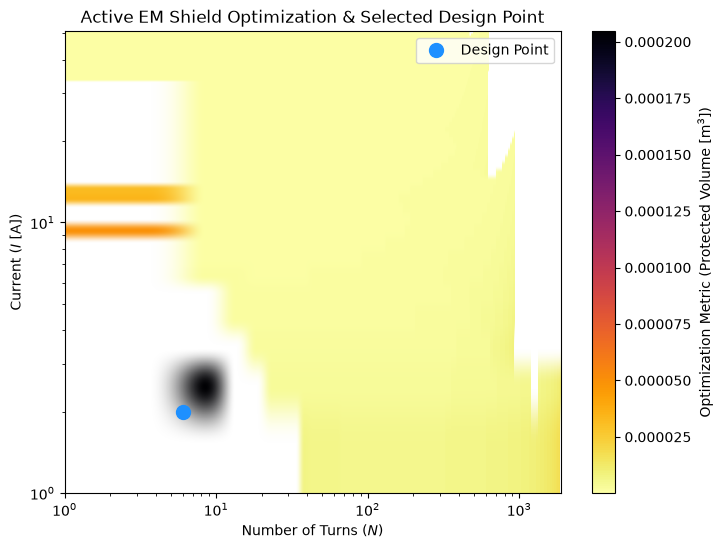

In [49]:
# ==========================================
# Feasibility Masking, Optimization Metric, and Optimal Design Point Extraction
# ==========================================

# --- Apply Feasibility Constraints (Masking) ---
# Filters out configurations exceeding critical current, geometrical height, radius limits, or spatial integration bounds
mask = (
    (I_s < (YBCO["Ic (A)"].values * u.A))
    &
    (H_s < H_max)
    &
    (R_s < R_max)
    &
    ((H_s**2 + (3**0.5 / 3 * H_s + 2 * R_s)**2)**0.5 < 2 * L_shield)
).astype(float)
mask[mask == 0] = np.nan

# --- Define Optimization Metric ---
# Maximizes the protected cylindrical volume envelope for feasible coil layouts
metric = mask * (np.pi * (R_s + W_s)**2 * H_s ).to_value(u.m**3)

# Locate the optimal index position maximizing the metric
opt = np.where(metric == np.nanmax(metric))

# --- Visualization: Optimization Metric Map with Optimal Design Point ---
plt.figure(figsize=(8, 6))
plt.imshow(
    np.nanmin(metric, axis=-1),             # Projected optimization metric along thickness axis
    extent=[N_s.value.min(), N_s.value.max(), I_s.to(u.A).value.min(), I_s.to(u.A).value.max()],
    origin='lower',
    aspect='auto',
    cmap='inferno_r',
)

# Plot the selected global optimum design point on the logarithmic map
plt.plot(N_s[opt], I_s[opt].to_value(u.A), "o", markersize=10, c="dodgerblue", label=f"Design Point")

plt.xlim(np.nanmin(N_s * mask), np.nanmax(N_s * mask))
plt.ylim(np.nanmin(I_s * mask).to_value(u.A), np.nanmax(I_s * mask).to_value(u.A))
plt.xlabel("Number of Turns ($N$)")
plt.ylabel("Current ($I$ [A])")
plt.xscale("log")
plt.yscale("log")
plt.colorbar(label=r"Optimization Metric (Protected Volume [m$^3$])")
plt.title("Active EM Shield Optimization & Selected Design Point")
plt.legend()
plt.show()

In [50]:
# --- Display Optimal Design Parameters ---
display(
    R_s[opt].to(u.mm),                      # Optimal inner coil radius
    W_s[opt].to(u.mm),                      # Optimal winding width
    T_s[opt].to(u.mm),                      # Optimal winding thickness
    H_s[opt].to(u.mm),                      # Optimal stack height (length)
    I_s[opt].to(u.A),                       # Optimal operating current
    I_s[opt].to(u.A) / (YBCO["Ic (A)"].values * u.A), # Operating current ratio (I / Ic)
    P_s[opt].to(u.mW),                      # Power dissipation at optimal point
    N_s[opt],                               # Optimal number of turns
    np.nanmin(metric) * u.dimensionless_unscaled # Metric baseline value
)

<Quantity [63.64849616] mm>

<Quantity [0.13793103] mm>

<Quantity [2.66984127] mm>

<Quantity [16.01904762] mm>

<Quantity [2.] A>

<Quantity [0.03900156]>

<Quantity [4.18049476] mW>

<Quantity [6.]>

<Quantity 1.10345024e-07>

## Verification of Preliminary Design

### Workspace Cleanup and Particle Dynamics Simulation Environment

Having isolated the optimal coil configuration, this section prepares the computational environment for the subsequent phase of the study: **charged particle trajectory simulation via the Lorentz force**.

**Environment Setup Workflow:**
1. **Workspace Pruning (`keep` list):** Extracts and stores only the critical physical and geometrical variables resulting from the optimization phase (such as optimal radius $R$, stack height $H$, winding width $t$, critical current density $J_0$, and solar wind speed $V_{\text{sw}}$), clearing all intermediate mesh arrays from global memory to free RAM.
2. **Memory Reclamation:** Executes explicit garbage collection (`gc.collect()`).
3. **Re-importing Simulation Dependencies:** Imports specialized libraries required for solving initial value problems (`scipy.integrate.solve_ivp`), spatial interpolation (`RegularGridInterpolator`), and advanced tensor rotations (`scipy.ndimage.rotate`) to model particle interactions against the generated magnetic field barrier.

In [ ]:
# ==========================================
# Workspace Cleanup and Particle Dynamics Simulation Environment
# ==========================================

# --- Extract Optimal Design Parameters into Scalar Variables ---
R = np.float32(R_s[opt][0].to_value(u.m))       # Optimal inner coil radius
H = np.float32(H_s[opt][0].to_value(u.m))       # Optimal coil stack height (length)
t = np.float32(W_s[opt][0].to_value(u.m))       # Optimal winding thickness / width
n = np.float32(YBCO["n"].values[0])             # Superconducting power-law exponent index (n)
Jc = np.float32((YBCO["Ic (A)"].values[0] * u.A / A_tape).to_value(u.A / u.m**2)) # Critical current density
J0 = Jc                                         # Baseline reference current density
Ec = np.float32((Vc_tape / L_s[opt])[0].to_value(u.V/u.m)) # Critical electric field threshold
L = np.float32(L_shield.to_value(u.m))          # Characteristic payload length scale (1U)
mu = np.float32(mu0.to_value(u.N /  u.A**2))    # Vacuum permeability constant
Vsw = v_sw.to_value(u.m/u.s)                    # Solar wind bulk velocity scalar

# --- Memory Management: Pruning Unused Global Variables ---
# Define the whitelist of essential variables to retain in memory
keep = {"R", "H", "t", "J0", "L", "mu", "n", "Jc", "Ec", "Vsw", "q_p", "m_p" "gc"}

# Iterate through global namespace and delete variables not in the keep list (excluding private/system names)
for name in list(globals().keys()):
    if name not in keep and not name.startswith("_"):
        del globals()[name]

# Trigger garbage collection to reclaim memory blocks from heavy mesh arrays
gc.collect()

# --- Re-import Dependencies for Particle Trajectory & Dynamics Simulation ---
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from tqdm import tqdm
import gc

# Specialized libraries for spatial interpolation and stiff ODE integration (Lorentz force propagation)
from scipy.interpolate import RegularGridInterpolator
from scipy.integrate import solve_ivp
import copy

### Simulation Domain Discretization and Spatial Grid Setup

With the optimal coil dimensions resolved, this section defines the 3D computational domain for particle trajectory propagation and magnetic field interpolation under the influence of the Lorentz force.

**Grid Setup & Domain Architecture:**
1. **Domain Dimensions (`Lx`, `Ly`, `Lz`):** Scaled relative to the characteristic payload length ($L = 1\,\text{U}$), defining an extended spatial volume to track particle entry, deflection, and interaction dynamics.
2. **Spatial Resolution (`h`):** Grid spacing step size set to $5\%$ of the characteristic length ($h = 0.05 L$).
3. **Node Counts (`Nx`, `Ny`, `Nz`):** Calculates the total number of grid nodes along each Cartesian axis using ceiling rounding.
4. **Relaxation Parameter (`k_sor`):** Computes the optimal successive over-relaxation (SOR) convergence factor based on maximum grid dimensions.
5. **Coordinate Arrays (`xs`, `ys`, `zs`) & Tensor Mesh (`X`, `Y`, `Z`):** Generates shifted and centered 1D spatial coordinates and combines them via `np.ix_` to form a dense 3D evaluation mesh.
6. **`plot` Function:** Generates three orthogonal slice projections (along X, Y, and Z axes) of the integrated current density magnitude, overlaying the $1\,\text{U}$ protected volume boundary (`Protected Volume`) to visually verify spatial accommodation.

In [52]:
# ==========================================
# Simulation Domain Discretization and Spatial Grid Setup
# ==========================================

# --- Define Spatial Domain Boundaries relative to Characteristic Length (L) ---
Lx = 10 * L                    # Total domain length along X-axis
Ly = 40 * L                    # Total domain length along Y-axis (extended upstream for solar wind flow)
Lz = 10 * L                    # Total domain length along Z-axis

# --- Grid Resolution ---
h = 0.05 * L                   # Spatial discretization step size (5% of L)

# --- Compute Number of Grid Nodes per Axis ---
Nx = np.ceil(Lx / h + 1).astype(int)
Ny = np.ceil(Ly / h + 1).astype(int)
Nz = np.ceil(Lz / h + 1).astype(int)

# --- Successive Over-Relaxation (SOR) Optimal Parameter ---
# Computes the acceleration factor for iterative solvers based on maximum grid dimensions
k_sor = 2 / (1 + np.sin(np.pi / np.max([Nx, Ny, Nz])))

# --- Construct 1D Coordinate Arrays ---
xs = np.linspace(-Lx/2, Lx/2, Nx, dtype=np.float32)       # X-axis coordinates centered on origin
ys = np.linspace(-Ly/4, 3*Ly/4, Ny, dtype=np.float32)     # Y-axis coordinates offset to capture upstream flow
zs = np.linspace(-Lz/2, Lz/2, Nz, dtype=np.float32)       # Z-axis coordinates centered on origin

# --- Generate 3D Mesh Grid using Indexed Arrays ---
X, Y, Z = np.ix_(xs, ys, zs)

In [53]:
def plot(Field, label):
    """
    Generates multi-axis orthogonal projection slices of a 3D vector tensor field 
    with logarithmic color scaling and protected volume reference boundaries.
    """
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    for i, (ax, axis_name, (a, b)) in enumerate(zip(axes, ["X", "Y", "Z"], [(Y,Z), (X,Z), (X,Y)])):

        # Sum vector norms along orthogonal axes
        var = np.sum(np.linalg.norm(Field, axis=-1), axis=i).T
        eps = np.finfo(float).eps
        img = ax.imshow(
            var + eps,
            extent=[a.min(), a.max(), b.min(), b.max()],
            origin='lower',
            aspect='auto',
            cmap='inferno',
            norm=LogNorm(vmin=np.nanmin(var + eps), vmax=np.nanmax(var + eps))
            )
        
        # Overlay the protected 1U volume boundaries
        ax.plot(
            np.array([1, 1,-1,-1,1]) * 0.5 * L,
            np.array([1,-1,-1, 1,1]) * 0.5 * L,
            c="dodgerblue",
            lw=1,
            label="Protected Volume"
        )
        
        ax.set_title(f"Field Slices along {axis_name} axis")
        ax.axis("equal")
        ax.axis("off")
        ax.legend()
        fig.colorbar(img, ax=ax, fraction=0.046, pad=0.04, label=label)
        
    plt.tight_layout()
    plt.show()

### 3D Current Density Vector Field Generation and Coil Array Placement

With the spatial domain established, this section models the 3D current density vector field (`J_shield`) corresponding to an arrangement of oriented superconducting coils positioned around the protected payload volume.

**Modeling Methodology:**
1. **`add_oriented_coil` Function:** Maps the analytical current density distribution onto the discretized 3D grid for a coil defined by an arbitrary position center, orientation axis vector (`axis_vec`), height, radius, and thickness. It computes axial/radial projections and assigns cross-product tangential current vectors (`tx, ty, tz`) scaled by current density ($J_0$).
2. **Symmetric Coil Array Configuration:** Iterates through discrete azimuth (`deg_xz`) and polar rotation angles (`deg_yz`) to place multiple oriented coils symmetrically around the core volume, accumulating their contributions into the global `J_shield` tensor.

In [54]:
# ==========================================
# 3D Current Density Vector Field Generation and Coil Array Placement
# ==========================================

def add_oriented_coil(J_field, value, center, axis_vec, X, Y, Z, height, radius, thickness, eps=h):
    """
    Adds the current density vector distribution of an arbitrarily oriented finite solenoid coil 
    onto the 3D computational grid.
    """
    # Normalize the orientation axis vector
    u = np.asarray(axis_vec, dtype=np.float32)
    u /= np.linalg.norm(u)
    ux, uy, uz = u

    # Compute coordinate offsets relative to the coil center
    dx = X - np.float32(center[0])
    dy = Y - np.float32(center[1])
    dz = Z - np.float32(center[2])

    # Project coordinates along the coil axis (axial coordinate)
    p_axi = dx * ux + dy * uy + dz * uz

    # Compute squared radial distance from the coil axis
    p_sq = dx**2 + dy**2 + dz**2
    radial_sq = np.maximum(0.0, p_sq - p_axi**2)

    # Define inner and outer radial boundaries including grid padding (eps)
    r_inner = radius - 0.5 * thickness - h
    r_outer = radius + 0.5 * thickness + h

    # Create spatial boolean mask for nodes residing within the coil winding geometry
    mask = (
        (radial_sq >= r_inner**2)
        & (radial_sq <= r_outer**2)
        & (np.abs(p_axi) <= 0.5 * height + h)
    )

    shape_3d = mask.shape
    dx_m = np.broadcast_to(dx, shape_3d)[mask]
    dy_m = np.broadcast_to(dy, shape_3d)[mask]
    dz_m = np.broadcast_to(dz, shape_3d)[mask]
    r_norm = np.sqrt(radial_sq[mask])

    # Compute tangential unit vectors for azimuthal current flow via cross product (u x r)
    tx = uy * dz_m - uz * dy_m
    ty = uz * dx_m - ux * dz_m
    tz = ux * dy_m - uy * dx_m

    valid = r_norm > 0.0
    inv_r = np.zeros_like(r_norm)
    inv_r[valid] = value / r_norm[valid]

    # Accumulate current density components into the global 3D vector field
    J_field[..., 0][mask] += tx * inv_r
    J_field[..., 1][mask] += ty * inv_r
    J_field[..., 2][mask] += tz * inv_r

    return J_field

100%|██████████| 3/3 [00:00<00:00,  6.47it/s]


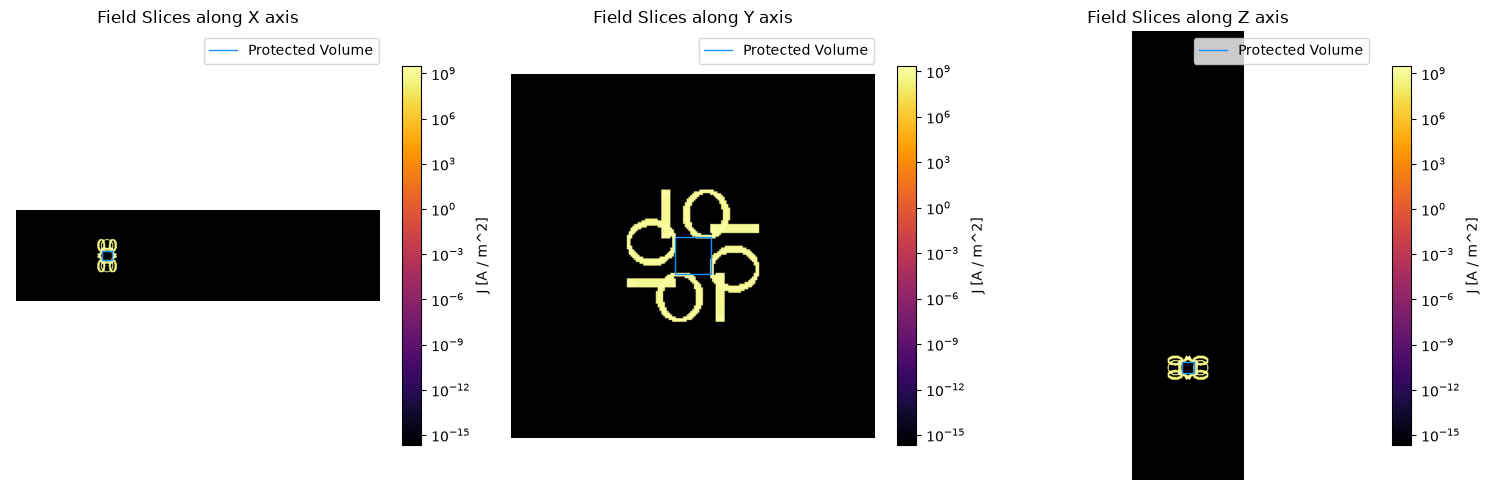

In [55]:
# --- Initialize Global 3D Current Density Tensor Field ---
J_shield = np.zeros((Nx, Ny, Nz, 3), dtype=np.float32)

# --- Define Coil Placement Offsets ---
x_offset = 0.5 * L + t + R
r_offset = (3**0.5 / 3.0) * H + t + R
z_cube = 0.0

# --- Populate Symmetric Coil Array via Rotational Loops ---
for deg_xz in [0.0, 90.0, 180.0, 270.0]:
    alpha = np.deg2rad(deg_xz)
    cos_a = np.cos(alpha)
    sin_a = np.sin(alpha)

    for deg_yz in tqdm([0.0, 120.0, 240.0]):
        theta = np.deg2rad(deg_yz)

        cx0 = x_offset
        cy0 = -r_offset * np.sin(theta)
        cz0 =  r_offset * np.cos(theta)
        
        ux0 = 0.0
        uy0 = -np.sin(theta)
        uz0 =  np.cos(theta)

        # Apply 3D coordinate transformations for symmetric orientation
        cx = cx0 * cos_a + cz0 * sin_a
        cy = cy0
        cz = (-cx0 * sin_a + cz0 * cos_a) + z_cube
        
        ux = ux0 * cos_a + uz0 * sin_a
        uy = uy0
        uz = -ux0 * sin_a + uz0 * cos_a
        
        # Add each oriented coil configuration to the shielding current tensor
        add_oriented_coil(
            J_field=J_shield,
            value=J0,
            center=(cx, cy, cz),
            axis_vec=(ux, uy, uz),
            X=X, Y=Y, Z=Z,
            height=H,
            radius=R,
            thickness=t
        )

# --- Visualize Current Density Distribution ---
plot(J_shield, "J [A / m^2]")

### Spectral Magnetostatics Solver ($B_{\text{fft}}$) and Superconducting Electric Field Formulation

To compute the full 3D magnetic induction vector field ($\mathbf{B}_{\text{shield}}$) and the induced electric field distribution within the superconducting tape windings, this section implements a high-performance Fast Fourier Transform (FFT) spectral solver and a power-law constitutive electric field model.

**Computational Workflow & Physics**
1. **Spectral Magnetostatics Solver (`B_fft`):** Applies zero-padding ($\text{pad\_factor} = 0.25$) to eliminate periodic boundary convolution artifacts, transforms the 3D current density tensor ($\mathbf{J}_{\text{shield}}$) into wave-number space via real FFT (`np.fft.rfftn`), and evaluates the Biot-Savart relation in Fourier space:
   $$\hat{\mathbf{B}}(\mathbf{k}) = \frac{j \mu_0}{\mathbf{k}^2} (\mathbf{k} \times \hat{\mathbf{J}}(\mathbf{k}))$$
   An inverse real FFT (`np.fft.irfftn`) maps the magnetic induction back to real space while stripping padding bounds.
2. **Magnetic Field Visualization:** Plots multi-axis orthogonal projection slices of the resulting magnetic flux density ($\mathbf{B}_{\text{shield}}$) in Tesla across the computational domain.
3. **Superconducting Electric Field ($\mathbf{E}_{\text{shield}}$):** Evaluates the non-linear electric field vector field across the coil windings using the power-law flux-flow resistivity model:
   $$\mathbf{E}_{\text{shield}} = E_c \left( \frac{\|\mathbf{J}_{\text{shield}}\|}{J_c} \right)^{n-1} \mathbf{J}_{\text{shield}}$$
   where $E_c$ is the critical electric field criterion, $J_c$ is the critical current density, and $n$ is the material power-law index.## 17. Spectral Magnetostatics Solver ($B_{\text{fft}}$) and Superconducting Electric Field Formulation

To compute the full 3D magnetic induction vector field ($\mathbf{B}_{\text{shield}}$) and the induced electric field distribution within the superconducting tape windings, this section implements a high-performance Fast Fourier Transform (FFT) spectral solver and a power-law constitutive electric field model.

**Computational Workflow & Physics:**
1. **Spectral Magnetostatics Solver (`B_fft`):** Applies zero-padding ($\text{pad\_factor} = 0.25$) to eliminate periodic boundary convolution artifacts, transforms the 3D current density tensor ($\mathbf{J}_{\text{shield}}$) into wave-number space via real FFT (`np.fft.rfftn`), and evaluates the Biot-Savart relation in Fourier space:
   $$\hat{\mathbf{B}}(\mathbf{k}) = \frac{j \mu_0}{\mathbf{k}^2} (\mathbf{k} \times \hat{\mathbf{J}}(\mathbf{k}))$$
   An inverse real FFT (`np.fft.irfftn`) maps the magnetic induction back to real space while stripping padding bounds.
2. **Magnetic Field Visualization:** Plots multi-axis orthogonal projection slices of the resulting magnetic flux density ($\mathbf{B}_{\text{shield}}$) in Tesla across the computational domain.
3. **Superconducting Electric Field ($\mathbf{E}_{\text{shield}}$):** Evaluates the non-linear electric field vector field across the coil windings using the power-law flux-flow resistivity model:
   $$\mathbf{E}_{\text{shield}} = E_c \left( \frac{\|\mathbf{J}_{\text{shield}}\|}{J_c} \right)^{n-1} \mathbf{J}_{\text{shield}}$$
   where $E_c$ is the critical electric field criterion, $J_c$ is the critical current density, and $n$ is the material power-law index.

In [56]:
# ==========================================
# Spectral Magnetostatics Solver (B_fft) & Electric Field Formulation
# ==========================================

def B_fft(J, mu0, h, pad_factor=0.25, dtype=np.float32):
    """
    Computes the 3D magnetic flux density vector field (B) from a given current density tensor (J) 
    using a padded Fast Fourier Transform (FFT) spectral convolution method.
    """
    Nx, Ny, Nz, _ = J.shape
    
    # Calculate padding sizes to eliminate periodic boundary convolution errors
    px = int(pad_factor * Nx)
    py = int(pad_factor * Ny)
    pz = int(pad_factor * Nz)

    Nx_p = Nx + 2 * px
    Ny_p = Ny + 2 * py
    Nz_p = Nz + 2 * pz

    def transform_component(comp_idx):
        """Zero-pads and performs forward 3D real FFT on a single current component."""
        pad_buf = np.zeros((Nx_p, Ny_p, Nz_p), dtype=dtype)
        pad_buf[px:px+Nx, py:py+Ny, pz:pz+Nz] = J[..., comp_idx]
        J_hat = np.fft.rfftn(pad_buf)
        del pad_buf
        gc.collect()
        return J_hat

    # Transform each Cartesian current density component into spectral space
    Jx_hat = transform_component(0)
    Jy_hat = transform_component(1)
    Jz_hat = transform_component(2)

    # Generate wave-number grid coordinates corresponding to spatial frequencies
    kx = (2 * np.pi * np.fft.fftfreq(Nx_p, d=h)).astype(dtype)
    ky = (2 * np.pi * np.fft.fftfreq(Ny_p, d=h)).astype(dtype)
    kz = (2 * np.pi * np.fft.rfftfreq(Nz_p, d=h)).astype(dtype)

    KX = kx[:, None, None]
    KY = ky[None, :, None]
    KZ = kz[None, None, :]

    K2 = KX**2 + KY**2 + KZ**2
    K2[0, 0, 0] = 1.0  # Avoid division by zero at zero-frequency mode

    B = np.empty((Nx, Ny, Nz, 3), dtype=dtype)
    factor_const = np.complex64(1j * mu0)

    # --- Solve for Bx Component ---
    B_hat = (factor_const / K2) * (KY * Jz_hat - KZ * Jy_hat)
    B_hat[0, 0, 0] = 0.0
    B[..., 0] = np.fft.irfftn(B_hat, s=(Nx_p, Ny_p, Nz_p))[px:px+Nx, py:py+Ny, pz:pz+Nz]
    del B_hat
    gc.collect()

    # --- Solve for By Component ---
    B_hat = (factor_const / K2) * (KZ * Jx_hat - KX * Jz_hat)
    B_hat[0, 0, 0] = 0.0
    B[..., 1] = np.fft.irfftn(B_hat, s=(Nx_p, Ny_p, Nz_p))[px:px+Nx, py:py+Ny, pz:pz+Nz]
    del B_hat, Jz_hat 
    gc.collect()

    # --- Solve for Bz Component ---
    B_hat = (factor_const / K2) * (KX * Jy_hat - KY * Jx_hat)
    B_hat[0, 0, 0] = 0.0
    B[..., 2] = np.fft.irfftn(B_hat, s=(Nx_p, Ny_p, Nz_p))[px:px+Nx, py:py+Ny, pz:pz+Nz]
    del B_hat, Jx_hat, Jy_hat, K2
    gc.collect()

    return B

/tmp/ipykernel_42157/3522866422.py:53: DeprecationWarning: `axes` should not be `None` if `s` is not `None` (Deprecated in NumPy 2.0). In a future version of NumPy, this will raise an error and `s[i]` will correspond to the size along the transformed axis specified by `axes[i]`. To retain current behaviour, pass a sequence [0, ..., k-1] to `axes` for an array of dimension k.
  B[..., 0] = np.fft.irfftn(B_hat, s=(Nx_p, Ny_p, Nz_p))[px:px+Nx, py:py+Ny, pz:pz+Nz]
/tmp/ipykernel_42157/3522866422.py:60: DeprecationWarning: `axes` should not be `None` if `s` is not `None` (Deprecated in NumPy 2.0). In a future version of NumPy, this will raise an error and `s[i]` will correspond to the size along the transformed axis specified by `axes[i]`. To retain current behaviour, pass a sequence [0, ..., k-1] to `axes` for an array of dimension k.
  B[..., 1] = np.fft.irfftn(B_hat, s=(Nx_p, Ny_p, Nz_p))[px:px+Nx, py:py+Ny, pz:pz+Nz]
/tmp/ipykernel_42157/3522866422.py:67: DeprecationWarning: `axes` shou

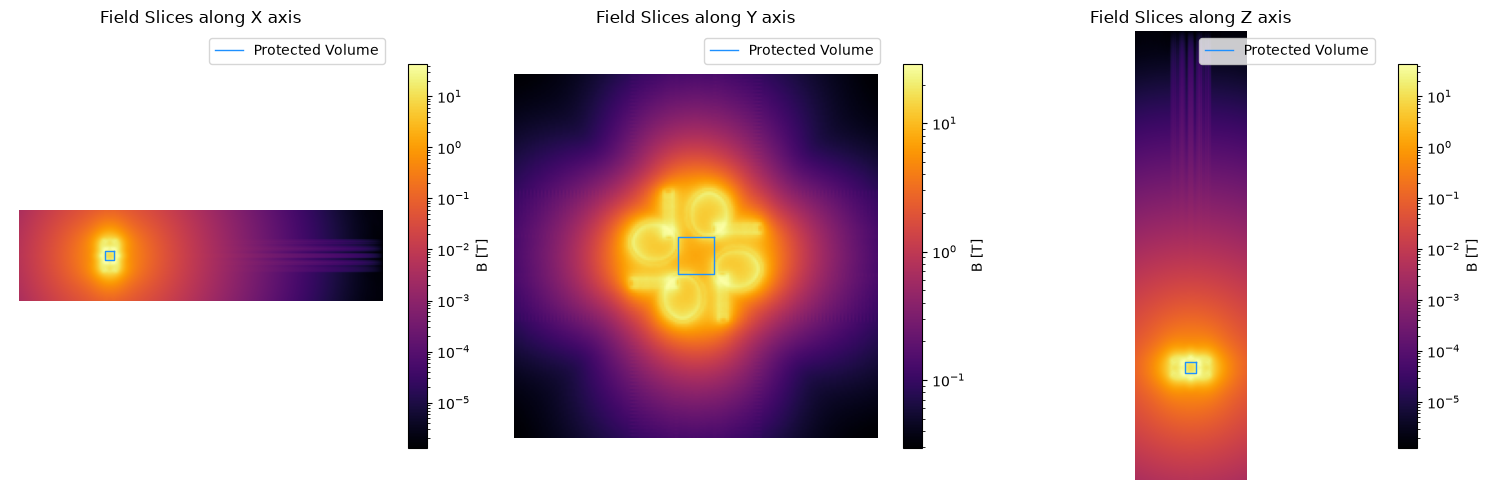

In [57]:
# --- Execute Spectral Magnetic Field Solver ---
B_shield = B_fft(J_shield, mu, h, 0.25)

# --- Visualize Computed Magnetic Induction Field ---
plot(B_shield, "B [T]")


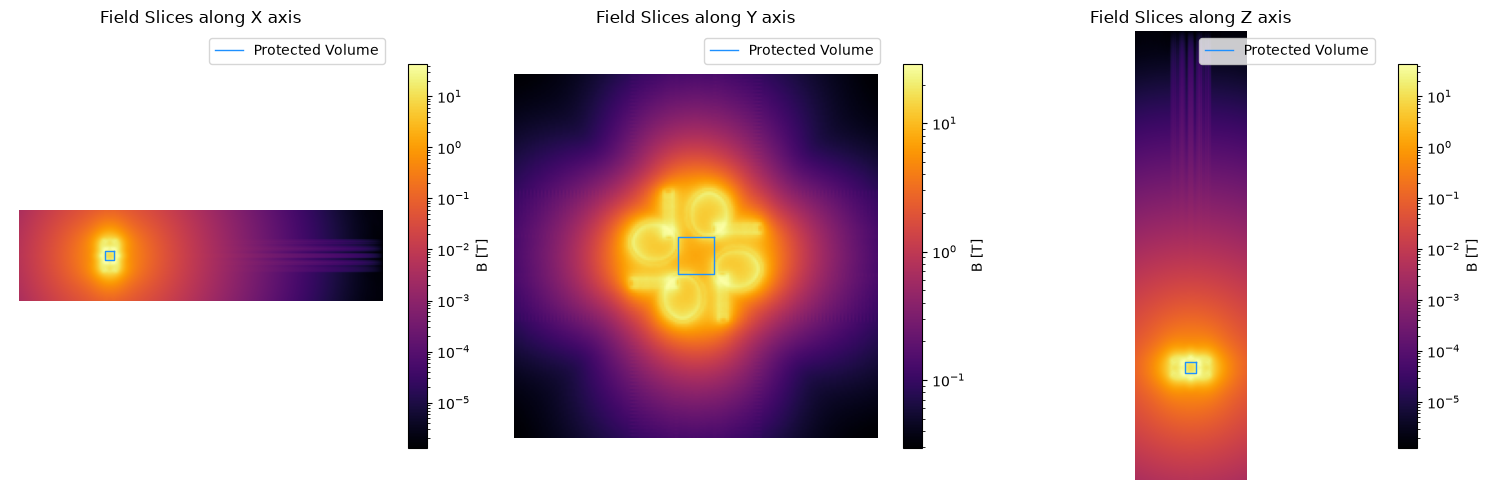

In [58]:
# --- Compute Electric Field Vector Distribution in Superconducting Coils ---
E_shield = (Ec * (np.linalg.norm(J_shield, axis=-1) / Jc)**(n - 1))[:,:,:,None] * J_shield

# --- Visualize Computed Electric Induction Field ---
plot(B_shield, "B [T]")


## Lorentz Force Trajectory Simulation and Charged Particle Dynamics

With the 3D magnetic ($\mathbf{B}_{\text{shield}}$) and electric ($\mathbf{E}_{\text{shield}}$) field distributions established across the domain, this final section sets up spatial interpolation functions and solves the relativistic/classical equations of motion for solar wind protons interacting with the active electromagnetic shield.

### Simulation Architecture:
1. **Spatial Interpolation (`RegularGridInterpolator`):** Constructs continuous vector interpolators (`B_interp`, `E_interp`) over the discrete spatial grid (`xs, ys, zs`), allowing real-time evaluation of electromagnetic fields at arbitrary particle coordinates with linear interpolation and zero out-of-bounds filling.
2. **Equation of Motion (`deriv`):** Implements the Lorentz force acceleration vector for protons (mass $m_p$, charge $q_p$) as an initial value problem ODE:
   $$\frac{d\mathbf{v}}{dt} = \frac{q_p}{m_p} \left( \mathbf{E} + \mathbf{v} \times \mathbf{B} \right)$$
3. **Trajectory Batch Integration (`solve_ivp`):** Iterates across discretized upstream injection points along the X and Z axes, propagating proton trajectories (`solve_ivp`) through the magnetostatic shielding barrier over a time span scaled by the solar wind bulk velocity ($V_{\text{sw}}$).
4. **Results Visualization:** Generates two diagnostic plots:
   * A time-series log plot tracking particle distance relative to the $1\,\text{U}$ protected payload envelope.
   * A 3D trajectory rendering (`Axes3D`) overlaying deflected proton paths (`magenta`) against the coil winding geometry (`black` voxel scatter) and the protected core volume (`dodgerblue`).

In [59]:
# --- 1. Construct Continuous Spatial Interpolators for B and E Fields ---
B_interp = RegularGridInterpolator(
    (xs, ys, zs), 
    B_shield, 
    method="linear", 
    bounds_error=False, 
    fill_value=0.0
)

E_interp = RegularGridInterpolator(
    (xs, ys, zs), 
    E_shield, 
    method="linear", 
    bounds_error=False, 
    fill_value=0.0
)

In [60]:
# ==========================================
# Lorentz Force Trajectory Simulation and Charged Particle Dynamics
# ==========================================
def deriv(t, y, q, m):
    """
    Computes the time derivatives of position (dr/dt) and velocity (dvdt) 
    governed by the Lorentz force law for a charged particle in electromagnetic fields.
    """
    r = y[:3]  # Position vector [x, y, z]
    v = y[3:]  # Velocity vector [vx, vy, vz]
    
    # Interpolate local magnetic and electric field vectors at particle position
    B = B_interp(r)[0]
    E = E_interp(r)[0]
    
    # Acceleration vector: dv/dt = (q/m) * (E + v x B)
    dvdt = q / m * (E + np.cross(v, B))
    drdt = v
    
    return np.concatenate([drdt, dvdt])

In [64]:
# --- 2. Execute Particle Trajectory Integration Sweep ---
SOL = []
CONST = []

# Loop over discretized upstream injection coordinates in X and Z axes
for xi in tqdm(xs[0:len(xs)//2:len(xs)//20]):
    for zi in zs[0:len(zs)//2:len(zs)//20]:

        # Initial state vector: position [xi, max_upstream_y, zi] and initial velocity [0, -Vsw, 0]
        y0 = np.array([xi, ys.max(), zi, 0, -Vsw, 0])

        # Integrate ODE initial value problem for each proton trajectory
        sol = solve_ivp(
            deriv,
            t_span=(0, 2 * Ly / Vsw),
            y0=y0,
            args=(q_p, m_p),
            # method='Radau', # Optional stiff solver method
            # rtol=1e-8,
            # atol=1e-8
        )
        SOL.append(sol)

100%|██████████| 10/10 [00:05<00:00,  1.96it/s]


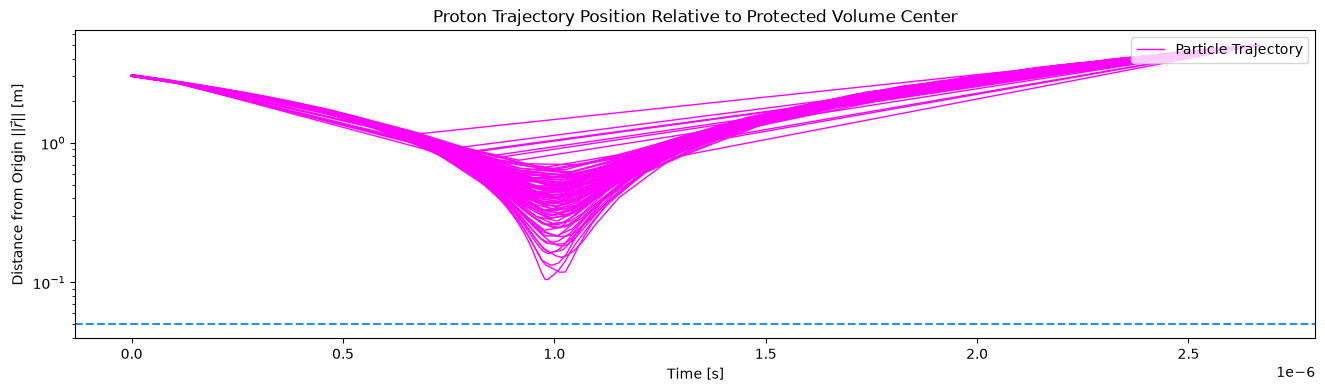

In [67]:
# --- 3. Visualization: Trajectory Distance vs. Time ---
plt.figure(figsize=(16,4))

for sol in SOL:
    plt.plot(sol.t, np.linalg.norm(sol.y[:3], axis=0), "-", lw=1, c="magenta")

plt.axhline(0.5 * L, c="dodgerblue", linestyle="--", label="Protected Volume Threshold")
plt.xlabel("Time [s]")
plt.ylabel(r"Distance from Origin $||\vec{r}||$ [m]")
plt.title("Proton Trajectory Position Relative to Protected Volume Center")
plt.yscale("log")
plt.legend(["Particle Trajectory"], loc="upper right")
plt.show()

/tmp/ipykernel_42157/281717259.py:14: UserWarning: The pixel maker ',' is not supported on scatter(); using a finite-sized square instead, which is not necessarily 1 pixel in size. Use the square marker 's' instead to suppress this warning.
  ax.scatter3D(xs[ix], ys[iy], zs[iz], marker=",", s=1, c="k", alpha=0.3, label="YBCO Coils")


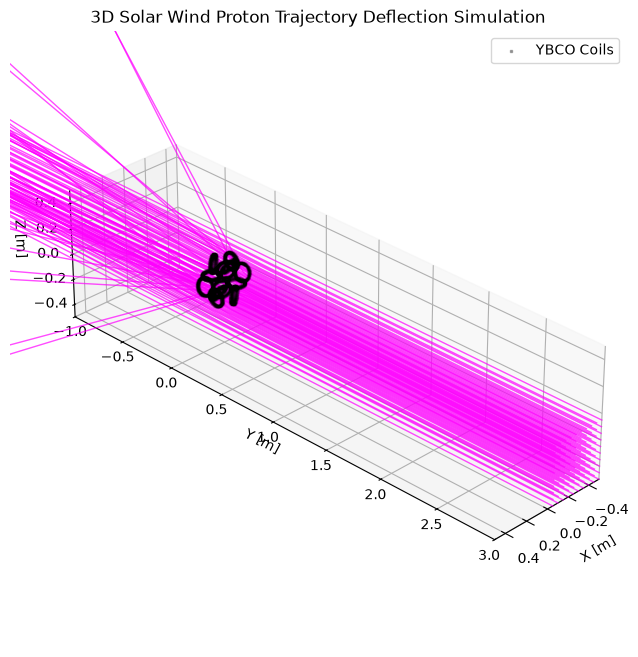

In [69]:
# --- 4. Visualization: 3D Spatial Trajectory Rendering ---
# Extract active coil voxel indices for 3D scatter plotting
Shield = (J_shield[..., 0]**2 + J_shield[..., 1]**2 + J_shield[..., 2]**2) > 0
ix, iy, iz = np.nonzero(Shield)

fig = plt.figure(figsize=(16, 8))
ax = fig.add_subplot(projection='3d')

# Plot each integrated proton trajectory path
for sol in SOL:
    ax.plot(sol.y[0], sol.y[1], sol.y[2], c="magenta", lw=1, alpha=0.7)

# Scatter plot of superconducting coil winding geometry
ax.scatter3D(xs[ix], ys[iy], zs[iz], marker=",", s=1, c="k", alpha=0.3, label="YBCO Coils")

ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.set_zlabel('Z [m]')

ax.set_xlim(xs.min(), xs.max())
ax.set_ylim(ys.min(), ys.max())
ax.set_zlim(zs.min(), zs.max())

ax.view_init(elev=30, azim=45)
ax.set_aspect("equal")
plt.title('3D Solar Wind Proton Trajectory Deflection Simulation')
plt.legend()
plt.show()

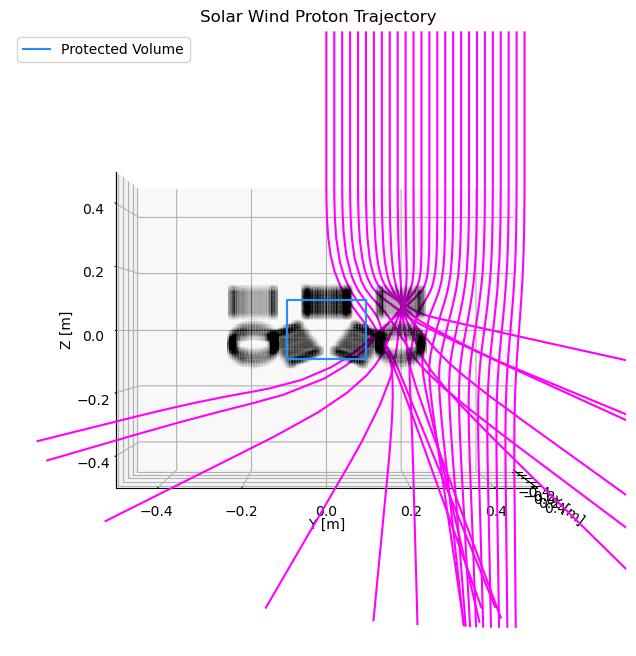

If the design constraints are changed and lower solar wind parameters are used, we can obtain deviations like those shown in this figure.